In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("train[1].csv")
df

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False
...,...,...,...,...,...
421565,45,98,2012-09-28,508.37,False
421566,45,98,2012-10-05,628.10,False
421567,45,98,2012-10-12,1061.02,False
421568,45,98,2012-10-19,760.01,False


In [3]:
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False


In [4]:
df.shape

(421570, 5)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  object 
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
dtypes: bool(1), float64(1), int64(2), object(1)
memory usage: 13.3+ MB


In [9]:
print(df.isnull().sum())

df["Date"] = pd.to_datetime(df["Date"])

# Aggregate weekly sales across stores and departments
sales = (
    df.groupby("Date", as_index=False)["Weekly_Sales"]
    .sum()
    .sort_values("Date")
)

sales.rename(
    columns={"Weekly_Sales": "Sales"},
    inplace=True
)

sales = sales.set_index("Date").asfreq("7D")

sales["Sales"] = sales["Sales"].interpolate()

print(sales.head())
print(sales.tail())

Store           0
Dept            0
Date            0
Weekly_Sales    0
IsHoliday       0
dtype: int64
                  Sales
Date                   
2010-02-05  49750740.50
2010-02-12  48336677.63
2010-02-19  48276993.78
2010-02-26  43968571.13
2010-03-05  46871470.30
                  Sales
Date                   
2012-09-28  43734899.40
2012-10-05  47566639.31
2012-10-12  46128514.25
2012-10-19  45122410.57
2012-10-26  45544116.29


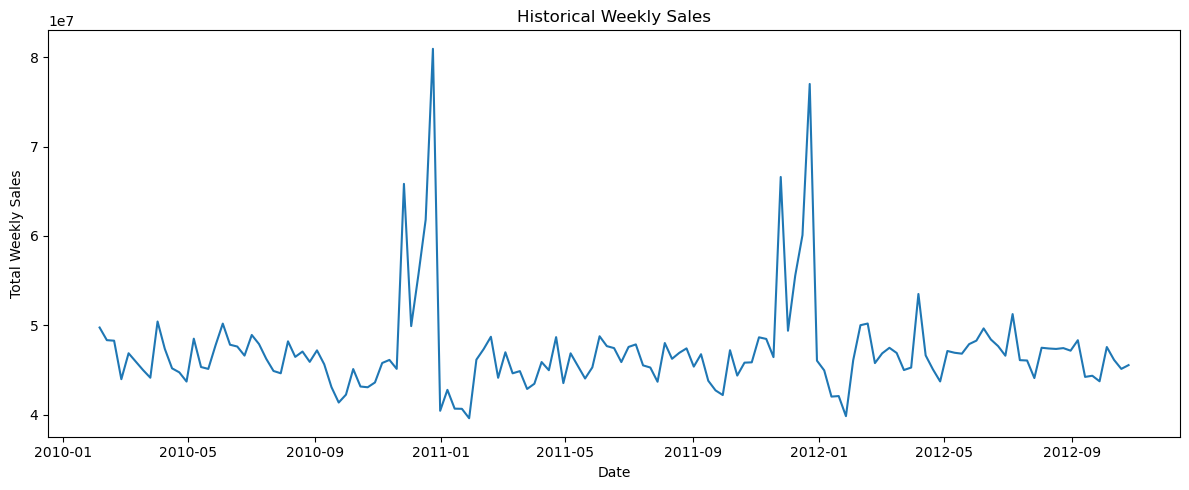

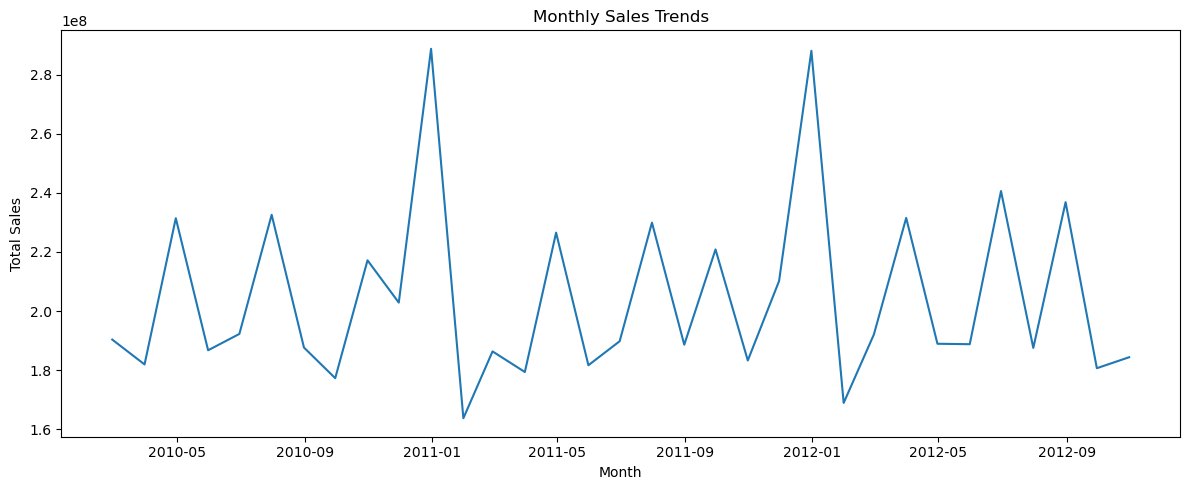

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(sales.index, sales["Sales"])
plt.title("Historical Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Total Weekly Sales")
plt.tight_layout()
plt.savefig("historical_sales.png")
plt.show()

# Monthly sales patterns
monthly_sales = sales["Sales"].resample("ME").sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values)
plt.title("Monthly Sales Trends")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.savefig("monthly_sales.png")
plt.show()

In [11]:
data = sales.copy()

data["Year"] = data.index.year
data["Month"] = data.index.month
data["Quarter"] = data.index.quarter
data["Week"] = data.index.isocalendar().week.astype(int)

# Lag features
data["Lag_1"] = data["Sales"].shift(1)
data["Lag_4"] = data["Sales"].shift(4)
data["Lag_52"] = data["Sales"].shift(52)

# Rolling averages based only on previous observations
data["Rolling_Mean_4"] = (
    data["Sales"].shift(1).rolling(4).mean()
)

data["Rolling_Mean_12"] = (
    data["Sales"].shift(1).rolling(12).mean()
)

data.dropna(inplace=True)

print(data.head())

                  Sales  Year  Month  Quarter  Week        Lag_1        Lag_4  \
Date                                                                            
2011-02-04  46153111.12  2011      2        1     5  39599852.99  42775787.77   
2011-02-11  47336192.79  2011      2        1     6  46153111.12  40673678.04   
2011-02-18  48716164.12  2011      2        1     7  47336192.79  40654648.03   
2011-02-25  44125859.84  2011      2        1     8  48716164.12  39599852.99   
2011-03-04  46980603.74  2011      3        1     9  44125859.84  46153111.12   

                 Lag_52  Rolling_Mean_4  Rolling_Mean_12  
Date                                                      
2011-02-04  49750740.50    4.092599e+07     5.079466e+07  
2011-02-11  48336677.63    4.177032e+07     5.079702e+07  
2011-02-18  48276993.78    4.343595e+07     5.098123e+07  
2011-02-25  43968571.13    4.545133e+07     4.955583e+07  
2011-03-04  46871470.30    4.658283e+07     4.907390e+07  


In [12]:
#split data chrnologically
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression

features = [
    "Year", "Month", "Quarter", "Week",
    "Lag_1", "Lag_4", "Lag_52",
    "Rolling_Mean_4", "Rolling_Mean_12"
]

X = data[features]
y = data["Sales"]

split_index = int(len(data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 72
Testing rows: 19


In [13]:
#train & compare forecasting model
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
}

results = []
predictions = {}

for name, model in models.items():

    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    predictions[name] = pred

    mae = mean_absolute_error(y_test, pred)

    rmse = np.sqrt(
        mean_squared_error(y_test, pred)
    )

    # Avoid division by zero in MAPE
    nonzero = y_test != 0

    mape = (
        np.mean(
            np.abs(
                (y_test[nonzero] - pred[nonzero])
                / y_test[nonzero]
            )
        ) * 100
    )

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE_Percent": mape
    })

    print(f"\n{name}")
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("MAPE:", round(mape, 2), "%")

results_df = pd.DataFrame(results)
print("\nModel Comparison:")
print(results_df)

results_df.to_csv(
    "forecast_model_comparison.csv", index=False
)


Linear Regression
MAE: 2191712.58
RMSE: 2365529.32
MAPE: 4.75 %

Random Forest
MAE: 1003400.13
RMSE: 1341864.6
MAPE: 2.14 %

Model Comparison:
               Model           MAE          RMSE  MAPE_Percent
0  Linear Regression  2.191713e+06  2.365529e+06      4.751106
1      Random Forest  1.003400e+06  1.341865e+06      2.140178


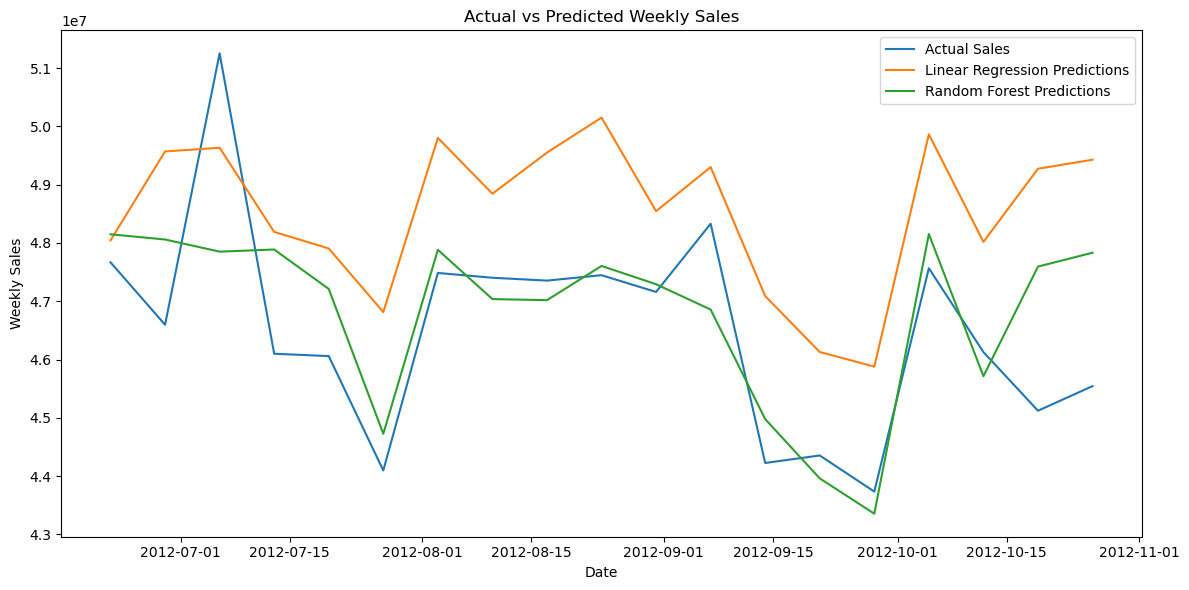

In [14]:
#plo actual vs predicted sales
plt.figure(figsize=(12, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Actual Sales"
)

for name, pred in predictions.items():
    plt.plot(
        y_test.index,
        pred,
        label=f"{name} Predictions"
    )

plt.title("Actual vs Predicted Weekly Sales")
plt.xlabel("Date")
plt.ylabel("Weekly Sales")
plt.legend()
plt.tight_layout()
plt.savefig("sales_forecast.png")
plt.show()

         Date  Forecast_Sales
0  2012-11-02    4.899232e+07
1  2012-11-09    4.820179e+07
2  2012-11-16    4.740669e+07
3  2012-11-23    6.269221e+07
4  2012-11-30    4.955200e+07
5  2012-12-07    5.258376e+07
6  2012-12-14    5.980786e+07
7  2012-12-21    6.997566e+07
8  2012-12-28    5.175113e+07
9  2013-01-04    4.801605e+07
10 2013-01-11    4.412479e+07
11 2013-01-18    4.295033e+07


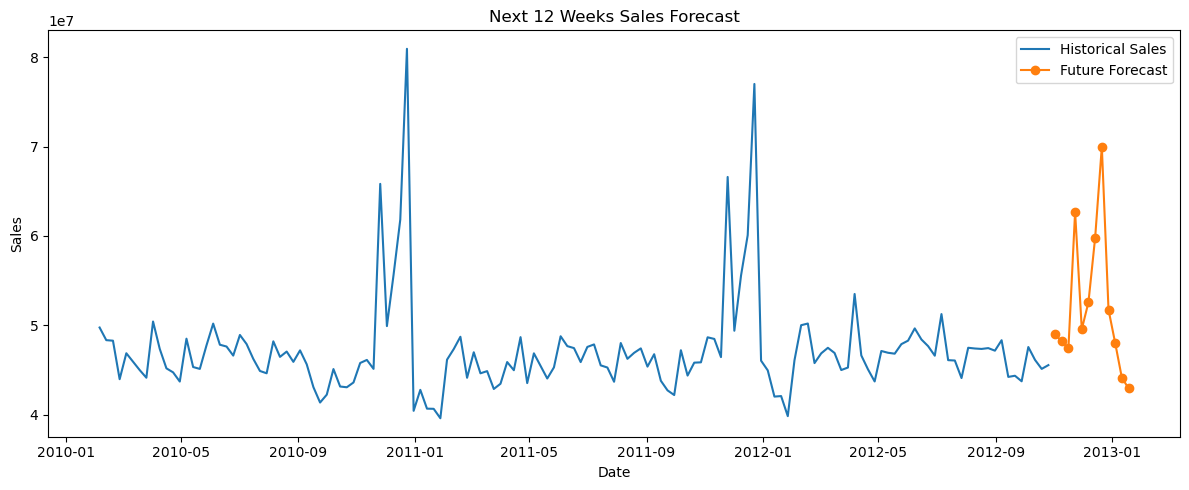

In [15]:
#Forecast future sales
from sklearn.base import clone

# Use the Random Forest model for the future forecast
forecast_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

forecast_model.fit(X_train, y_train)

history = sales["Sales"].copy()
future_predictions = []

last_date = history.index[-1]

for step in range(1, 13):

    next_date = last_date + pd.Timedelta(weeks=step)

    row = pd.DataFrame(
        index=[next_date]
    )

    row["Year"] = next_date.year
    row["Month"] = next_date.month
    row["Quarter"] = next_date.quarter
    row["Week"] = int(next_date.isocalendar().week)

    row["Lag_1"] = history.iloc[-1]
    row["Lag_4"] = history.iloc[-4]
    row["Lag_52"] = history.iloc[-52]

    row["Rolling_Mean_4"] = history.iloc[-4:].mean()
    row["Rolling_Mean_12"] = history.iloc[-12:].mean()

    future_sales = forecast_model.predict(
        row[features]
    )[0]

    future_predictions.append({
        "Date": next_date,
        "Forecast_Sales": future_sales
    })

    # Append the forecast for use in the next step
    history.loc[next_date] = future_sales

forecast_df = pd.DataFrame(future_predictions)

print(forecast_df)

forecast_df.to_csv(
    "future_sales_forecast.csv", index=False
)

plt.figure(figsize=(12, 5))
plt.plot(sales.index, sales["Sales"], label="Historical Sales")
plt.plot(
    forecast_df["Date"],
    forecast_df["Forecast_Sales"],
    marker="o",
    label="Future Forecast"
)

plt.title("Next 12 Weeks Sales Forecast")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.savefig("future_sales_forecast.png")
plt.show()